## 1. Setup

In [ ]:
! pip install emoji
import kagglehub
import csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import re
import string
import json
import emoji
from bs4 import BeautifulSoup
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import accuracy_score, f1_score
import torch
import torch.nn as nn
import random
from torch.utils.data import Dataset, DataLoader

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 7.3 MB/s  0:00:00


In [ ]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## 2. Dataset

In [ ]:
# Download latest version
path = kagglehub.dataset_download("debarshichanda/goemotions")

print("Path to dataset files:", path)
path_to_set_1 = "/kaggle/input/goemotions/data/full_dataset/goemotions_1.csv"
path_to_set_2 = "/kaggle/input/goemotions/data/full_dataset/goemotions_2.csv"
path_to_set_3 = "/kaggle/input/goemotions/data/full_dataset/goemotions_3.csv"

Using Colab cache for faster access to the 'goemotions' dataset.
Path to dataset files: /kaggle/input/goemotions


In [ ]:
paths = [path_to_set_1]
# paths = [path_to_set_1, path_to_set_2]
# paths = [path_to_set_1, path_to_set_2, path_to_set_3]

dataset = pd.concat(
    [pd.read_csv(path, delimiter=',') for path in paths],
    ignore_index=True
)
dataset

,text,id,author,subreddit,link_id,parent_id,created_utc,rater_id,example_very_unclear,admiration,...,love,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral
0,That game hurt.,eew5j0j,Brdd9,nrl,t3_ajis4z,t1_eew18eq,1.548381e+09,1,False,0,...,0,0,0,0,0,0,0,1,0,0
1,>sexuality shouldn’t be a grouping category I...,eemcysk,TheGreen888,unpopularopinion,t3_ai4q37,t3_ai4q37,1.548084e+09,37,True,0,...,0,0,0,0,0,0,0,0,0,0
2,"You do right, if you don't care then fuck 'em!",ed2mah1,Labalool,confessions,t3_abru74,t1_ed2m7g7,1.546428e+09,37,False,0,...,0,0,0,0,0,0,0,0,0,1
3,Man I love reddit.,eeibobj,MrsRobertshaw,facepalm,t3_ahulml,t3_ahulml,1.547965e+09,18,False,0,...,1,0,0,0,0,0,0,0,0,0
4,"[NAME] was nowhere near them, he was by the Fa...",eda6yn6,American_Fascist713,starwarsspeculation,t3_ackt2f,t1_eda65q2,1.546669e+09,2,False,0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
69995,"It's about fucking time, hope this is real.",eeuoyeh,DudeImMacGyver,worldnews,t3_ajcbgq,t3_ajcbgq,1.548346e+09,19,False,0,...,0,0,0,0,0,0,0,0,0,0
69996,This is great! Can anyone make a request with ...,eer0igi,Dirkus777,gay,t3_aiqhx1,t3_aiqhx1,1.548223e+09,55,False,1,...,0,0,0,0,0,0,0,0,0,0
69997,I’m sorry. Can you please explain what are the...,eebxspf,menjav,DebateAnAtheist,t3_ah451r,t1_eeblb39,1.547787e+09,5,False,0,...,0,0,0,0,0,0,0,0,0,0
69998,No but it should be,edjf4v2,heputmystuffinjello,DunderMifflin,t3_adpkeq,t1_edjasoe,1.546922e+09,51,False,0,...,0,0,0,0,0,0,0,0,0,1


## 3. Preprocessing

In [ ]:
new_df = dataset[["text", "example_very_unclear", "admiration",
                   "amusement", "anger", "annoyance", "approval", "caring",
                   "confusion", "curiosity", "desire", "disappointment",
                   "disapproval", "disgust", "embarrassment", "excitement",
                   "fear", "gratitude", "grief", "joy", "love", "nervousness",
                   "optimism", "pride", "realization", "relief", "remorse",
                   "sadness", "surprise", "neutral"]].copy()

In [ ]:
contraction_mapping = {"ain't": "is not", "aren't": "are not","can't": "cannot", "'cause": "because", "could've": "could have", "couldn't": "could not",
                       "didn't": "did not",  "doesn't": "does not", "don't": "do not", "hadn't": "had not", "hasn't": "has not", "haven't": "have not",
                       "he'd": "he would","he'll": "he will", "he's": "he is", "how'd": "how did", "how'd'y": "how do you", "how'll": "how will",
                       "how's": "how is",  "I'd": "I would", "I'd've": "I would have", "I'll": "I will", "I'll've": "I will have","I'm": "I am",
                       "I've": "I have", "i'd": "i would", "i'd've": "i would have", "i'll": "i will",  "i'll've": "i will have","i'm": "i am",
                       "i've": "i have", "isn't": "is not", "it'd": "it would", "it'd've": "it would have", "it'll": "it will", "it'll've": "it will have",
                       "it's": "it is", "let's": "let us", "ma'am": "madam", "mayn't": "may not", "might've": "might have","mightn't": "might not",
                       "mightn't've": "might not have", "must've": "must have", "mustn't": "must not", "mustn't've": "must not have", "needn't": "need not",
                       "needn't've": "need not have","o'clock": "of the clock", "oughtn't": "ought not", "oughtn't've": "ought not have", "shan't": "shall not",
                       "sha'n't": "shall not", "shan't've": "shall not have", "she'd": "she would", "she'd've": "she would have", "she'll": "she will",
                       "she'll've": "she will have", "she's": "she is", "should've": "should have", "shouldn't": "should not", "shouldn't've": "should not have",
                       "so've": "so have","so's": "so as", "this's": "this is","that'd": "that would", "that'd've": "that would have", "that's": "that is",
                       "there'd": "there would", "there'd've": "there would have", "there's": "there is", "here's": "here is","they'd": "they would",
                       "they'd've": "they would have", "they'll": "they will", "they'll've": "they will have", "they're": "they are", "they've": "they have",
                       "to've": "to have", "wasn't": "was not", "we'd": "we would", "we'd've": "we would have", "we'll": "we will", "we'll've": "we will have",
                       "we're": "we are", "we've": "we have", "weren't": "were not", "what'll": "what will", "what'll've": "what will have",
                       "what're": "what are",  "what's": "what is", "what've": "what have", "when's": "when is", "when've": "when have", "where'd": "where did",
                       "where's": "where is", "where've": "where have", "who'll": "who will", "who'll've": "who will have", "who's": "who is",
                       "who've": "who have", "why's": "why is", "why've": "why have", "will've": "will have", "won't": "will not", "won't've": "will not have",
                       "would've": "would have", "wouldn't": "would not", "wouldn't've": "would not have", "y'all": "you all", "y'all'd": "you all would",
                       "y'all'd've": "you all would have","y'all're": "you all are","y'all've": "you all have","you'd": "you would", "you'd've": "you would have",
                       "you'll": "you will", "you'll've": "you will have", "you're": "you are", "you've": "you have", 'u.s':'america', 'e.g':'for example'}

punct = [',', '.', '"', ':', ')', '(', '-', '!', '?', '|', ';', "'", '$', '&', '/', '[', ']', '>', '%', '=', '#', '*', '+', '\\', '•',  '~', '@', '£',
 '·', '_', '{', '}', '©', '^', '®', '`',  '<', '→', '°', '€', '™', '›',  '♥', '←', '×', '§', '″', '′', 'Â', '█', '½', 'à', '…',
 '“', '★', '”', '–', '●', 'â', '►', '−', '¢', '²', '¬', '░', '¶', '↑', '±', '¿', '▾', '═', '¦', '║', '―', '¥', '▓', '—', '‹', '─',
 '▒', '：', '¼', '⊕', '▼', '▪', '†', '■', '’', '▀', '¨', '▄', '♫', '☆', 'é', '¯', '♦', '¤', '▲', 'è', '¸', '¾', 'Ã', '⋅', '‘', '∞',
 '∙', '）', '↓', '、', '│', '（', '»', '，', '♪', '╩', '╚', '³', '・', '╦', '╣', '╔', '╗', '▬', '❤', 'ï', 'Ø', '¹', '≤', '‡', '√', ]

punct_mapping = {"‘": "'", "₹": "e", "´": "'", "°": "", "€": "e", "™": "tm", "√": " sqrt ", "×": "x", "²": "2", "—": "-", "–": "-", "’": "'", "_": "-",
                 "`": "'", '“': '"', '”': '"', '“': '"', "£": "e", '∞': 'infinity', 'θ': 'theta', '÷': '/', 'α': 'alpha', '•': '.', 'à': 'a', '−': '-',
                 'β': 'beta', '∅': '', '³': '3', 'π': 'pi', '!':' '}

mispell_dict = {'colour': 'color', 'centre': 'center', 'favourite': 'favorite', 'travelling': 'traveling', 'counselling': 'counseling', 'theatre': 'theater',
                'cancelled': 'canceled', 'labour': 'labor', 'organisation': 'organization', 'wwii': 'world war 2', 'citicise': 'criticize', 'youtu ': 'youtube ',
                'Qoura': 'Quora', 'sallary': 'salary', 'Whta': 'What', 'narcisist': 'narcissist', 'howdo': 'how do', 'whatare': 'what are', 'howcan': 'how can',
                'howmuch': 'how much', 'howmany': 'how many', 'whydo': 'why do', 'doI': 'do I', 'theBest': 'the best', 'howdoes': 'how does',
                'mastrubation': 'masturbation', 'mastrubate': 'masturbate', "mastrubating": 'masturbating', 'pennis': 'penis', 'Etherium': 'Ethereum',
                'narcissit': 'narcissist', 'bigdata': 'big data', '2k17': '2017', '2k18': '2018', 'qouta': 'quota', 'exboyfriend': 'ex boyfriend',
                'airhostess': 'air hostess', "whst": 'what', 'watsapp': 'whatsapp', 'demonitisation': 'demonetization', 'demonitization': 'demonetization',
                'demonetisation': 'demonetization'}

In [ ]:
def clean_text(text):
    '''Clean emoji, Make text lowercase, remove text in square brackets,remove links,remove punctuation
    and remove words containing numbers.'''
    text = emoji.demojize(text)
    text = re.sub(r'\:(.*?)\:','',text)
    text = str(text).lower()    #Making Text Lowercase
    text = re.sub('\[.*?\]', '', text)
    #The next 2 lines remove html text
    text = BeautifulSoup(text, 'lxml').get_text()
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub('<.*?>+', '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    return text

def clean_contractions(text, mapping):
    '''Clean contraction using contraction mapping'''
    specials = ["’", "‘", "´", "`"]
    for s in specials:
        text = text.replace(s, "'")
    for word in mapping.keys():
        if ""+word+"" in text:
            text = text.replace(""+word+"", ""+mapping[word]+"")
    #Remove Punctuations
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    # creating a space between a word and the punctuation following it
    # eg: "he is a boy." => "he is a boy ."
    text = re.sub(r"([?.!,¿])", r" \1 ", text)
    text = re.sub(r'[" "]+', " ", text)
    return text

def clean_special_chars(text, punct, mapping):
    '''Cleans special characters present(if any)'''
    for p in mapping:
        text = text.replace(p, mapping[p])

    for p in punct:
        text = text.replace(p, f' {p} ')

    specials = {'\u200b': ' ', '…': ' ... ', '\ufeff': '', 'करना': '', 'है': ''}
    for s in specials:
        text = text.replace(s, specials[s])

    return text

def correct_spelling(x, dic):
    '''Corrects common spelling errors'''
    for word in dic.keys():
        x = x.replace(word, dic[word])
    return x

def remove_space(text):
    '''Removes awkward spaces'''
    #Removes awkward spaces
    text = text.strip()
    text = text.split()
    return " ".join(text)

def text_preprocessing_pipeline(text):
    '''Cleaning and parsing the text.'''
    text = clean_text(text)
    text = clean_contractions(text, contraction_mapping)
    text = clean_special_chars(text, punct, punct_mapping)
    text = correct_spelling(text, mispell_dict)
    # replacing everything with space except (a-z, A-Z, ".", "?", "!", ",", "'")
    text = re.sub(r"[^a-zA-Z?.!,¿']+", " ", text)
    text = remove_space(text)
    return text

<>:7: SyntaxWarning: invalid escape sequence '\['
<>:10: SyntaxWarning: invalid escape sequence '\S'
<>:13: SyntaxWarning: invalid escape sequence '\w'
<>:7: SyntaxWarning: invalid escape sequence '\['
<>:10: SyntaxWarning: invalid escape sequence '\S'
<>:13: SyntaxWarning: invalid escape sequence '\w'
/tmp/ipykernel_3116/1829598573.py:7: SyntaxWarning: invalid escape sequence '\['
  text = re.sub('\[.*?\]', '', text)
/tmp/ipykernel_3116/1829598573.py:10: SyntaxWarning: invalid escape sequence '\S'
  text = re.sub('https?://\S+|www\.\S+', '', text)
/tmp/ipykernel_3116/1829598573.py:13: SyntaxWarning: invalid escape sequence '\w'
  text = re.sub('\w*\d\w*', '', text)


In [ ]:
new_df["preprocessed_text"] = new_df["text"].apply(text_preprocessing_pipeline)


,text,example_very_unclear,admiration,amusement,anger,annoyance,approval,caring,confusion,curiosity,...,nervousness,optimism,pride,realization,relief,remorse,sadness,surprise,neutral,preprocessed_text
0,That game hurt.,False,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,that game hurt
1,>sexuality shouldn’t be a grouping category I...,True,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,sexuality should not be a grouping category it...
2,"You do right, if you don't care then fuck 'em!",False,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,you do right if you do not care then fuck em
3,Man I love reddit.,False,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,man i love reddit
4,"[NAME] was nowhere near them, he was by the Fa...",False,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,was nowhere near them he was by the falcon
5,Right? Considering it’s such an important docu...,False,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,right considering it is such an important docu...
6,"He isn't as big, but he's still quite popular....",False,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,he is not as big but he is still quite popular...
7,That's crazy; I went to a super [RELIGION] hig...,False,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,that is crazy i went to a super high school an...
8,that's adorable asf,False,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,that is adorable asf
9,"""Sponge Blurb Pubs Quaw Haha GURR ha AAa!"" fin...",False,0,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,sponge blurb pubs quaw haha gurr ha aaa finale...


In [ ]:
new_df[['text', 'preprocessed_text']].head()

,text,preprocessed_text
0,That game hurt.,that game hurt
1,>sexuality shouldn’t be a grouping category I...,sexuality should not be a grouping category it...
2,"You do right, if you don't care then fuck 'em!",you do right if you do not care then fuck em
3,Man I love reddit.,man i love reddit
4,"[NAME] was nowhere near them, he was by the Fa...",was nowhere near them he was by the falcon


## 4. Data Visualization

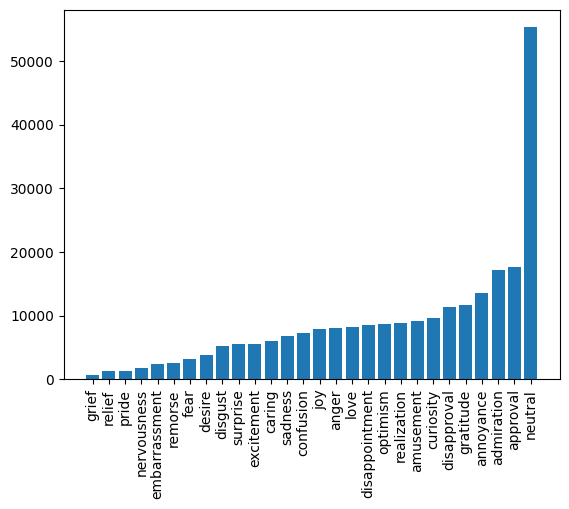

In [ ]:
emotions = ["admiration",
                   "amusement", "anger", "annoyance", "approval", "caring",
                   "confusion", "curiosity", "desire", "disappointment",
                   "disapproval", "disgust", "embarrassment", "excitement",
                   "fear", "gratitude", "grief", "joy", "love", "nervousness",
                   "optimism", "pride", "realization", "relief", "remorse",
                   "sadness", "surprise", "neutral"]
emotion_counts = new_df[emotions].sum().astype(int).to_dict()
sorted_emotion_counts = {key: value for key, value in sorted(emotion_counts.items(), key=lambda item: item[1])}
plt.bar(range(len(sorted_emotion_counts)), list(sorted_emotion_counts.values()), align='center')
plt.xticks(range(len(sorted_emotion_counts)), list(sorted_emotion_counts.keys()))
plt.xticks(rotation=90)
plt.show()

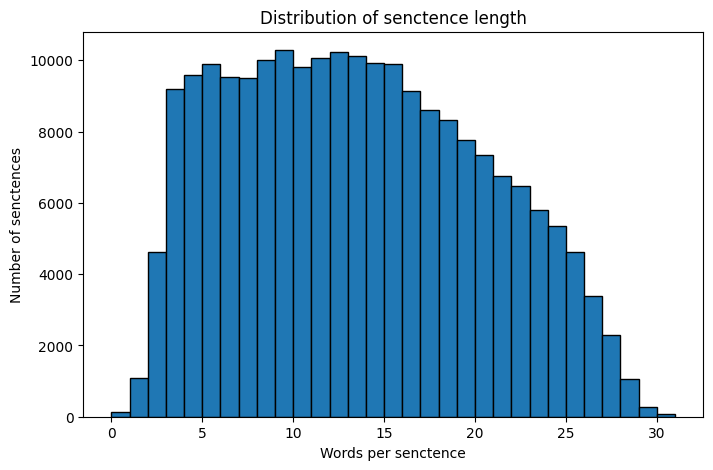

In [ ]:
sentence_lenght = new_df["preprocessed_text"].str.split().str.len()
plt.figure(figsize=(8, 5))
plt.hist(sentence_lenght, bins=range(0, sentence_lenght.max()), edgecolor="black")
plt.xlabel("Words per senctence")
plt.ylabel("Number of senctences")
plt.title("Distribution of senctence length")
plt.show()

## 5. Train / validation / test split

In [ ]:
from sklearn.model_selection import train_test_split

emotion_cols = ['admiration', 'amusement', 'anger', 'annoyance', 'approval', 'caring',
                 'confusion', 'curiosity', 'desire', 'disappointment', 'disapproval',
                 'disgust', 'embarrassment', 'excitement', 'fear', 'gratitude', 'grief',
                 'joy', 'love', 'nervousness', 'optimism', 'pride', 'realization',
                 'relief', 'remorse', 'sadness', 'surprise', 'neutral']

X = new_df["preprocessed_text"]
y = new_df[emotion_cols]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.3, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

print(f"Train: {X_train.shape[0]} rows")
print(f"Validation: {X_val.shape[0]} rows")
print(f"Test: {X_test.shape[0]} rows")

Train: 147857 rows
Validation: 31684 rows
Test: 31684 rows


## 6. Text representations

In [ ]:
max_features=10000      # keep only the top N most frequent words (cap vocab size)
min_df=2                # ignore words that appear in fewer than 2 documents
max_df=0.95             # ignore words that appear in more than 95% of documents (too common)
stop_words='english'    # remove common English stopwords
ngram_range=(1, 1)      # (1,1) = unigrams only; (1,2) = unigrams + bigrams


# Token indicators: binary CountVectorizer (word present/absent, no counts)
token_vectorizer = CountVectorizer(max_features=max_features, min_df=min_df, max_df=max_df, stop_words='english', ngram_range=(1, 1), binary=True)
X_train_token = token_vectorizer.fit_transform(X_train)
X_val_token = token_vectorizer.transform(X_val)
X_test_token = token_vectorizer.transform(X_test)

# Bag of words: counts
bow_vectorizer = CountVectorizer(max_features=max_features, min_df=min_df, max_df=max_df, stop_words='english', ngram_range=(1, 1))
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_val_bow = bow_vectorizer.transform(X_val)
X_test_bow = bow_vectorizer.transform(X_test)

# NEW
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer(max_features=max_features, min_df=min_df, max_df=max_df, stop_words='english', ngram_range=(1, 1))
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_val_tfidf = tfidf_vectorizer.transform(X_val)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

token_vectorizer_bigram = CountVectorizer(max_features=max_features, min_df=min_df, max_df=max_df, stop_words='english', ngram_range=(1, 2), binary=True)
X_train_token_bigram = token_vectorizer_bigram.fit_transform(X_train)
vocabulary = token_vectorizer_bigram.get_feature_names_out()
num_bigrams = sum(' ' in word for word in vocabulary)
print(f"number of BiGrams: {num_bigrams}")
X_val_token_bigram = token_vectorizer_bigram.transform(X_val)
X_test_token_bigram = token_vectorizer_bigram.transform(X_test)

number of BiGrams: 2882


## 7. Models

In [ ]:
# No hidden layer MLP
class EmotionClassifierNoHidden(nn.Module):
    def __init__(self, input_dim=10000, output_dim=28):
        super(EmotionClassifierNoHidden, self).__init__()
        self.linear = nn.Linear(input_dim, output_dim)

    def forward(self, x):
        return self.linear(x)

# Dropout random gekozen dus ook even kijken

# Single hidden layer MLP

# Jullie hadden 5000 input dims, hier 10000, dus ook nakijken
class EmotionClassifierHidden(nn.Module):
    def __init__(self, input_dim=10000, hidden_dim=256, output_dim=28, dropout=0.5):
        super(EmotionClassifierHidden, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc2(x)


# NEW: Second hidden layer MLP
class EmotionClassifierDeepMLP(nn.Module):
    def __init__(self, input_dim=10000, hidden_dim=256, output_dim=28, dropout=0.5):
        super(EmotionClassifierDeepMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.fc3 = nn.Linear(hidden_dim // 2, output_dim)

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        x = self.relu(self.fc2(x))
        x = self.dropout(x)
        return self.fc3(x)

## 8. Dataset, pos_weight, training loop, evaluation

In [ ]:
class SparseDataset(Dataset):
    def __init__(self, X_sparse, y):
        self.X_sparse = X_sparse
        self.y = torch.tensor(y.values if hasattr(y, "values") else y, dtype=torch.float32)

    def __len__(self):
        return self.X_sparse.shape[0]

    def __getitem__(self, idx):
        row = torch.tensor(self.X_sparse[idx].toarray().squeeze(), dtype=torch.float32)
        return row, self.y[idx]


def make_pos_weight(y_train):
    pos_counts = y_train.sum(axis=0)
    neg_counts = len(y_train) - pos_counts
    pos_weight = np.sqrt(neg_counts / pos_counts)
    return torch.tensor(pos_weight.values if hasattr(pos_weight, "values") else pos_weight,
                         dtype=torch.float32)


def train_model(model, train_loader, val_loader, pos_weight, num_epochs=5, lr=0.001):
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    for epoch in range(num_epochs):
        model.train()
        train_loss = 0.0
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for X_batch, y_batch in val_loader:
                outputs = model(X_batch)
                val_loss += criterion(outputs, y_batch).item()

        print(f"Epoch {epoch+1}/{num_epochs} - train_loss: {train_loss/len(train_loader):.4f} "
              f"- val_loss: {val_loss/len(val_loader):.4f}")

    return model


def evaluate_model(model, data_loader, threshold=0.35):
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for X_batch, y_batch in data_loader:
            outputs = torch.sigmoid(model(X_batch))
            preds = (outputs >= threshold).float()
            all_preds.append(preds)
            all_targets.append(y_batch)

    y_pred = torch.cat(all_preds).numpy()
    y_true = torch.cat(all_targets).numpy()

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1_micro": f1_score(y_true, y_pred, average="micro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
    }

## 9. Cross-validation

The checklist wants architectures compared with each other, and representations compared with
each other — **not** a full cross-comparison of every representation against every
architecture. That needs only **5 CV runs**, not 9:

- **Architecture comparison** (representation held fixed at bag of words): log-linear, MLP,
  deep MLP → 3 runs.
- **Representation comparison** (architecture held fixed at the single-hidden-layer MLP):
  token indicators, bag of words, TF-IDF → 3 runs.
- `bow + MLP` is needed by both comparisons, so it's written once and reused → 3 + 3 − 1 = 5
  runs total.

In [ ]:
# Shared setup — run this once before any of the 5 combo cells below
X_train_text = X_train.reset_index(drop=True)
y_train_arr = y_train.reset_index(drop=True)

VECTORIZER_KWARGS = dict(max_features=10000, min_df=2, max_df=0.95,
                          stop_words='english', ngram_range=(1, 1))

### CV 1/6 — Evaluating: Bag of words × Log-linear (no hidden layer)

**Comparing:** representation = `bow` (Bag of words), architecture = `EmotionClassifierNoHidden` (Log-linear (no hidden layer)). **Used for:** Architecture comparison. **Metric:** f1_macro per fold. **Result stored in:** `fold_scores_bow_loglinear`.

In [ ]:
# Split in 5 folds
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics_bow_loglinear = []

# Itereer over 5 folds, elke iteratie een fold als validation
for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_text)):
    X_fold_train_text = X_train_text.iloc[train_idx]
    X_fold_val_text = X_train_text.iloc[val_idx]
    y_fold_train = y_train_arr.iloc[train_idx]
    y_fold_val = y_train_arr.iloc[val_idx]

    # Per fold vectorizen om elke validation set van de fold nieuw te houden om data lek te voorkomen
    fold_vectorizer = CountVectorizer(**VECTORIZER_KWARGS)
    X_fold_train = fold_vectorizer.fit_transform(X_fold_train_text)
    X_fold_val = fold_vectorizer.transform(X_fold_val_text)

    fold_train_loader = DataLoader(SparseDataset(X_fold_train, y_fold_train), batch_size=64, shuffle=True)
    fold_val_loader = DataLoader(SparseDataset(X_fold_val, y_fold_val), batch_size=64)

    # Elke fold trainen
    pos_weight = make_pos_weight(y_fold_train)
    model = EmotionClassifierNoHidden(input_dim=X_fold_train.shape[1])
    model = train_model(model, fold_train_loader, fold_val_loader, pos_weight, num_epochs=5)

    # Metrics per fold
    metrics = evaluate_model(model, fold_val_loader)
    print(f"[Bag of words x Log-linear (no hidden layer)] Fold {fold_idx+1}:")
    print(f"  Accuracy (exact match): {metrics['accuracy']:.4f}")
    print(f"  Micro F1:               {metrics['f1_micro']:.4f}")
    print(f"  Macro F1:               {metrics['f1_macro']:.4f}")
    print(f"  Weighted F1:            {metrics['f1_weighted']:.4f}")
    fold_metrics_bow_loglinear.append(metrics)

# Mean across folds, printed in the same layout as a single-split report
mean_accuracy = np.mean([m["accuracy"] for m in fold_metrics_bow_loglinear])
mean_f1_micro = np.mean([m["f1_micro"] for m in fold_metrics_bow_loglinear])
mean_f1_macro = np.mean([m["f1_macro"] for m in fold_metrics_bow_loglinear])
mean_f1_weighted = np.mean([m["f1_weighted"] for m in fold_metrics_bow_loglinear])

print()
print("Bag of words x Log-linear (no hidden layer) — mean over 5 folds")
print(f"Accuracy (exact match): {mean_accuracy:.4f}")
print(f"Micro F1:               {mean_f1_micro:.4f}")
print(f"Macro F1:               {mean_f1_macro:.4f}")
print(f"Weighted F1:            {mean_f1_weighted:.4f}")

# Macro F1 per fold, kept separately since section 10's ROPE comparisons need one metric
fold_scores_bow_loglinear = [m["f1_macro"] for m in fold_metrics_bow_loglinear]

Epoch 1/5 - train_loss: 0.5192 - val_loss: 0.4420
Epoch 2/5 - train_loss: 0.4067 - val_loss: 0.4098
Epoch 3/5 - train_loss: 0.3691 - val_loss: 0.3959
Epoch 4/5 - train_loss: 0.3447 - val_loss: 0.3905
Epoch 5/5 - train_loss: 0.3272 - val_loss: 0.3899
[Bag of words x Log-linear (no hidden layer)] Fold 1:
  Accuracy (exact match): 0.2085
  Micro F1:               0.3910
  Macro F1:               0.3191
  Weighted F1:            0.3798
Epoch 1/5 - train_loss: 0.5188 - val_loss: 0.4421
Epoch 2/5 - train_loss: 0.4070 - val_loss: 0.4093
Epoch 3/5 - train_loss: 0.3694 - val_loss: 0.3947
Epoch 4/5 - train_loss: 0.3450 - val_loss: 0.3887
Epoch 5/5 - train_loss: 0.3278 - val_loss: 0.3875
[Bag of words x Log-linear (no hidden layer)] Fold 2:
  Accuracy (exact match): 0.2156
  Micro F1:               0.3935
  Macro F1:               0.3205
  Weighted F1:            0.3837
Epoch 1/5 - train_loss: 0.5187 - val_loss: 0.4445
Epoch 2/5 - train_loss: 0.4066 - val_loss: 0.4125
Epoch 3/5 - train_loss: 0.36

### CV 2/6 — Evaluating: Bag of words × Single-hidden-layer MLP

**Comparing:** representation = `bow` (Bag of words), architecture = `EmotionClassifierHidden` (Single-hidden-layer MLP). **Used for:** Architecture comparison + Representation comparison (shared). **Metric:** f1_macro per fold. **Result stored in:** `fold_scores_bow_mlp`.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics_bow_mlp = []

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_text)):
    X_fold_train_text = X_train_text.iloc[train_idx]
    X_fold_val_text = X_train_text.iloc[val_idx]
    y_fold_train = y_train_arr.iloc[train_idx]
    y_fold_val = y_train_arr.iloc[val_idx]

    fold_vectorizer = CountVectorizer(**VECTORIZER_KWARGS)
    X_fold_train = fold_vectorizer.fit_transform(X_fold_train_text)
    X_fold_val = fold_vectorizer.transform(X_fold_val_text)

    fold_train_loader = DataLoader(SparseDataset(X_fold_train, y_fold_train), batch_size=64, shuffle=True)
    fold_val_loader = DataLoader(SparseDataset(X_fold_val, y_fold_val), batch_size=64)

    pos_weight = make_pos_weight(y_fold_train)
    model = EmotionClassifierHidden(input_dim=X_fold_train.shape[1])
    model = train_model(model, fold_train_loader, fold_val_loader, pos_weight, num_epochs=5)

    metrics = evaluate_model(model, fold_val_loader)
    print(f"[Bag of words x Single-hidden-layer MLP] Fold {fold_idx+1}:")
    print(f"  Accuracy (exact match): {metrics['accuracy']:.4f}")
    print(f"  Micro F1:               {metrics['f1_micro']:.4f}")
    print(f"  Macro F1:               {metrics['f1_macro']:.4f}")
    print(f"  Weighted F1:            {metrics['f1_weighted']:.4f}")
    fold_metrics_bow_mlp.append(metrics)

# Mean across folds, printed in the same layout as a single-split report
mean_accuracy = np.mean([m["accuracy"] for m in fold_metrics_bow_mlp])
mean_f1_micro = np.mean([m["f1_micro"] for m in fold_metrics_bow_mlp])
mean_f1_macro = np.mean([m["f1_macro"] for m in fold_metrics_bow_mlp])
mean_f1_weighted = np.mean([m["f1_weighted"] for m in fold_metrics_bow_mlp])

print()
print("Bag of words x Single-hidden-layer MLP — mean over 5 folds")
print(f"Accuracy (exact match): {mean_accuracy:.4f}")
print(f"Micro F1:               {mean_f1_micro:.4f}")
print(f"Macro F1:               {mean_f1_macro:.4f}")
print(f"Weighted F1:            {mean_f1_weighted:.4f}")

# Macro F1 per fold, kept separately since section 10's ROPE comparisons need one metric
fold_scores_bow_mlp = [m["f1_macro"] for m in fold_metrics_bow_mlp]

Epoch 1/5 - train_loss: 0.4117 - val_loss: 0.3626
Epoch 2/5 - train_loss: 0.3417 - val_loss: 0.3558
Epoch 3/5 - train_loss: 0.3151 - val_loss: 0.3612
Epoch 4/5 - train_loss: 0.2966 - val_loss: 0.3698
Epoch 5/5 - train_loss: 0.2831 - val_loss: 0.3801
[Bag of words x Single-hidden-layer MLP] Fold 1:
  Accuracy (exact match): 0.1487
  Micro F1:               0.3753
  Macro F1:               0.3165
  Weighted F1:            0.3780
Epoch 1/5 - train_loss: 0.4117 - val_loss: 0.3604
Epoch 2/5 - train_loss: 0.3427 - val_loss: 0.3529
Epoch 3/5 - train_loss: 0.3157 - val_loss: 0.3561
Epoch 4/5 - train_loss: 0.2973 - val_loss: 0.3639
Epoch 5/5 - train_loss: 0.2834 - val_loss: 0.3738
[Bag of words x Single-hidden-layer MLP] Fold 2:
  Accuracy (exact match): 0.1478
  Micro F1:               0.3750
  Macro F1:               0.3226
  Weighted F1:            0.3838
Epoch 1/5 - train_loss: 0.4104 - val_loss: 0.3655
Epoch 2/5 - train_loss: 0.3416 - val_loss: 0.3598
Epoch 3/5 - train_loss: 0.3147 - val_l

### CV 3/6 — Evaluating: Bag of words × Two-hidden-layer MLP

**Comparing:** representation = `bow` (Bag of words), architecture = `EmotionClassifierDeepMLP` (Two-hidden-layer MLP). **Used for:** Architecture comparison. **Metric:** f1_macro per fold. **Result stored in:** `fold_scores_bow_deepmlp`.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics_bow_deepmlp = []

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_text)):
    X_fold_train_text = X_train_text.iloc[train_idx]
    X_fold_val_text = X_train_text.iloc[val_idx]
    y_fold_train = y_train_arr.iloc[train_idx]
    y_fold_val = y_train_arr.iloc[val_idx]

    fold_vectorizer = CountVectorizer(**VECTORIZER_KWARGS)
    X_fold_train = fold_vectorizer.fit_transform(X_fold_train_text)
    X_fold_val = fold_vectorizer.transform(X_fold_val_text)

    fold_train_loader = DataLoader(SparseDataset(X_fold_train, y_fold_train), batch_size=64, shuffle=True)
    fold_val_loader = DataLoader(SparseDataset(X_fold_val, y_fold_val), batch_size=64)

    pos_weight = make_pos_weight(y_fold_train)
    model = EmotionClassifierDeepMLP(input_dim=X_fold_train.shape[1])
    model = train_model(model, fold_train_loader, fold_val_loader, pos_weight, num_epochs=5)

    metrics = evaluate_model(model, fold_val_loader)
    print(f"[Bag of words x Two-hidden-layer MLP] Fold {fold_idx+1}:")
    print(f"  Accuracy (exact match): {metrics['accuracy']:.4f}")
    print(f"  Micro F1:               {metrics['f1_micro']:.4f}")
    print(f"  Macro F1:               {metrics['f1_macro']:.4f}")
    print(f"  Weighted F1:            {metrics['f1_weighted']:.4f}")
    fold_metrics_bow_deepmlp.append(metrics)

# Mean across folds, printed in the same layout as a single-split report
mean_accuracy = np.mean([m["accuracy"] for m in fold_metrics_bow_deepmlp])
mean_f1_micro = np.mean([m["f1_micro"] for m in fold_metrics_bow_deepmlp])
mean_f1_macro = np.mean([m["f1_macro"] for m in fold_metrics_bow_deepmlp])
mean_f1_weighted = np.mean([m["f1_weighted"] for m in fold_metrics_bow_deepmlp])

print()
print("Bag of words x Two-hidden-layer MLP — mean over 5 folds")
print(f"Accuracy (exact match): {mean_accuracy:.4f}")
print(f"Micro F1:               {mean_f1_micro:.4f}")
print(f"Macro F1:               {mean_f1_macro:.4f}")
print(f"Weighted F1:            {mean_f1_weighted:.4f}")

# Macro F1 per fold, kept separately since section 10's ROPE comparisons need one metric
fold_scores_bow_deepmlp = [m["f1_macro"] for m in fold_metrics_bow_deepmlp]

Epoch 1/5 - train_loss: 0.4328 - val_loss: 0.3766
Epoch 2/5 - train_loss: 0.3732 - val_loss: 0.3638
Epoch 3/5 - train_loss: 0.3505 - val_loss: 0.3602
Epoch 4/5 - train_loss: 0.3341 - val_loss: 0.3615
Epoch 5/5 - train_loss: 0.3206 - val_loss: 0.3654
[Bag of words x Two-hidden-layer MLP] Fold 1:
  Accuracy (exact match): 0.1291
  Micro F1:               0.3538
  Macro F1:               0.3002
  Weighted F1:            0.3680
Epoch 1/5 - train_loss: 0.4346 - val_loss: 0.3770
Epoch 2/5 - train_loss: 0.3749 - val_loss: 0.3611
Epoch 3/5 - train_loss: 0.3505 - val_loss: 0.3565
Epoch 4/5 - train_loss: 0.3344 - val_loss: 0.3566
Epoch 5/5 - train_loss: 0.3217 - val_loss: 0.3584
[Bag of words x Two-hidden-layer MLP] Fold 2:
  Accuracy (exact match): 0.1295
  Micro F1:               0.3599
  Macro F1:               0.3074
  Weighted F1:            0.3740
Epoch 1/5 - train_loss: 0.4322 - val_loss: 0.3791
Epoch 2/5 - train_loss: 0.3718 - val_loss: 0.3662
Epoch 3/5 - train_loss: 0.3486 - val_loss: 0

### CV 4/6 — Evaluating: Token indicators × Single-hidden-layer MLP

**Comparing:** representation = `token` (Token indicators), architecture = `EmotionClassifierHidden` (Single-hidden-layer MLP). **Used for:** Representation comparison. **Metric:** f1_macro per fold. **Result stored in:** `fold_scores_token_mlp`.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics_token_mlp = []

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_text)):
    X_fold_train_text = X_train_text.iloc[train_idx]
    X_fold_val_text = X_train_text.iloc[val_idx]
    y_fold_train = y_train_arr.iloc[train_idx]
    y_fold_val = y_train_arr.iloc[val_idx]

    fold_vectorizer = CountVectorizer(binary=True, **VECTORIZER_KWARGS)
    X_fold_train = fold_vectorizer.fit_transform(X_fold_train_text)
    X_fold_val = fold_vectorizer.transform(X_fold_val_text)

    fold_train_loader = DataLoader(SparseDataset(X_fold_train, y_fold_train), batch_size=64, shuffle=True)
    fold_val_loader = DataLoader(SparseDataset(X_fold_val, y_fold_val), batch_size=64)

    pos_weight = make_pos_weight(y_fold_train)
    model = EmotionClassifierHidden(input_dim=X_fold_train.shape[1])
    model = train_model(model, fold_train_loader, fold_val_loader, pos_weight, num_epochs=5)

    metrics = evaluate_model(model, fold_val_loader)
    print(f"[Token indicators x Single-hidden-layer MLP] Fold {fold_idx+1}:")
    print(f"  Accuracy (exact match): {metrics['accuracy']:.4f}")
    print(f"  Micro F1:               {metrics['f1_micro']:.4f}")
    print(f"  Macro F1:               {metrics['f1_macro']:.4f}")
    print(f"  Weighted F1:            {metrics['f1_weighted']:.4f}")
    fold_metrics_token_mlp.append(metrics)

# Mean across folds, printed in the same layout as a single-split report
mean_accuracy = np.mean([m["accuracy"] for m in fold_metrics_token_mlp])
mean_f1_micro = np.mean([m["f1_micro"] for m in fold_metrics_token_mlp])
mean_f1_macro = np.mean([m["f1_macro"] for m in fold_metrics_token_mlp])
mean_f1_weighted = np.mean([m["f1_weighted"] for m in fold_metrics_token_mlp])

print()
print("Token indicators x Single-hidden-layer MLP — mean over 5 folds")
print(f"Accuracy (exact match): {mean_accuracy:.4f}")
print(f"Micro F1:               {mean_f1_micro:.4f}")
print(f"Macro F1:               {mean_f1_macro:.4f}")
print(f"Weighted F1:            {mean_f1_weighted:.4f}")

# Macro F1 per fold, kept separately since section 10's ROPE comparisons need one metric
fold_scores_token_mlp = [m["f1_macro"] for m in fold_metrics_token_mlp]

Epoch 1/5 - train_loss: 0.4112 - val_loss: 0.3611
Epoch 2/5 - train_loss: 0.3417 - val_loss: 0.3552
Epoch 3/5 - train_loss: 0.3147 - val_loss: 0.3598
Epoch 4/5 - train_loss: 0.2964 - val_loss: 0.3679
Epoch 5/5 - train_loss: 0.2828 - val_loss: 0.3792
[Token indicators x Single-hidden-layer MLP] Fold 1:
  Accuracy (exact match): 0.1435
  Micro F1:               0.3671
  Macro F1:               0.3154
  Weighted F1:            0.3777
Epoch 1/5 - train_loss: 0.4112 - val_loss: 0.3601
Epoch 2/5 - train_loss: 0.3421 - val_loss: 0.3522
Epoch 3/5 - train_loss: 0.3157 - val_loss: 0.3554
Epoch 4/5 - train_loss: 0.2967 - val_loss: 0.3631
Epoch 5/5 - train_loss: 0.2831 - val_loss: 0.3735
[Token indicators x Single-hidden-layer MLP] Fold 2:
  Accuracy (exact match): 0.1504
  Micro F1:               0.3766
  Macro F1:               0.3224
  Weighted F1:            0.3830
Epoch 1/5 - train_loss: 0.4114 - val_loss: 0.3652
Epoch 2/5 - train_loss: 0.3410 - val_loss: 0.3590
Epoch 3/5 - train_loss: 0.3144

### CV 5/6 — Evaluating: TF-IDF × Single-hidden-layer MLP

**Comparing:** representation = `tfidf` (TF-IDF), architecture = `EmotionClassifierHidden` (Single-hidden-layer MLP). **Used for:** Representation comparison. **Metric:** f1_macro per fold. **Result stored in:** `fold_scores_tfidf_mlp`.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics_tfidf_mlp = []

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_text)):
    X_fold_train_text = X_train_text.iloc[train_idx]
    X_fold_val_text = X_train_text.iloc[val_idx]
    y_fold_train = y_train_arr.iloc[train_idx]
    y_fold_val = y_train_arr.iloc[val_idx]

    fold_vectorizer = TfidfVectorizer(**VECTORIZER_KWARGS)
    X_fold_train = fold_vectorizer.fit_transform(X_fold_train_text)
    X_fold_val = fold_vectorizer.transform(X_fold_val_text)

    fold_train_loader = DataLoader(SparseDataset(X_fold_train, y_fold_train), batch_size=64, shuffle=True)
    fold_val_loader = DataLoader(SparseDataset(X_fold_val, y_fold_val), batch_size=64)

    pos_weight = make_pos_weight(y_fold_train)
    model = EmotionClassifierHidden(input_dim=X_fold_train.shape[1])
    model = train_model(model, fold_train_loader, fold_val_loader, pos_weight, num_epochs=5)

    metrics = evaluate_model(model, fold_val_loader)
    print(f"[TF-IDF x Single-hidden-layer MLP] Fold {fold_idx+1}:")
    print(f"  Accuracy (exact match): {metrics['accuracy']:.4f}")
    print(f"  Micro F1:               {metrics['f1_micro']:.4f}")
    print(f"  Macro F1:               {metrics['f1_macro']:.4f}")
    print(f"  Weighted F1:            {metrics['f1_weighted']:.4f}")
    fold_metrics_tfidf_mlp.append(metrics)

# Mean across folds, printed in the same layout as a single-split report
mean_accuracy = np.mean([m["accuracy"] for m in fold_metrics_tfidf_mlp])
mean_f1_micro = np.mean([m["f1_micro"] for m in fold_metrics_tfidf_mlp])
mean_f1_macro = np.mean([m["f1_macro"] for m in fold_metrics_tfidf_mlp])
mean_f1_weighted = np.mean([m["f1_weighted"] for m in fold_metrics_tfidf_mlp])

print()
print("TF-IDF x Single-hidden-layer MLP — mean over 5 folds")
print(f"Accuracy (exact match): {mean_accuracy:.4f}")
print(f"Micro F1:               {mean_f1_micro:.4f}")
print(f"Macro F1:               {mean_f1_macro:.4f}")
print(f"Weighted F1:            {mean_f1_weighted:.4f}")

# Macro F1 per fold, kept separately since section 10's ROPE comparisons need one metric
fold_scores_tfidf_mlp = [m["f1_macro"] for m in fold_metrics_tfidf_mlp]

Epoch 1/5 - train_loss: 0.4281 - val_loss: 0.3716
Epoch 2/5 - train_loss: 0.3513 - val_loss: 0.3567
Epoch 3/5 - train_loss: 0.3216 - val_loss: 0.3559
Epoch 4/5 - train_loss: 0.3023 - val_loss: 0.3594
Epoch 5/5 - train_loss: 0.2877 - val_loss: 0.3669
[TF-IDF x Single-hidden-layer MLP] Fold 1:
  Accuracy (exact match): 0.1334
  Micro F1:               0.3687
  Macro F1:               0.3157
  Weighted F1:            0.3769
Epoch 1/5 - train_loss: 0.4287 - val_loss: 0.3700
Epoch 2/5 - train_loss: 0.3518 - val_loss: 0.3534
Epoch 3/5 - train_loss: 0.3229 - val_loss: 0.3527
Epoch 4/5 - train_loss: 0.3031 - val_loss: 0.3559
Epoch 5/5 - train_loss: 0.2876 - val_loss: 0.3621
[TF-IDF x Single-hidden-layer MLP] Fold 2:
  Accuracy (exact match): 0.1265
  Micro F1:               0.3677
  Macro F1:               0.3211
  Weighted F1:            0.3813
Epoch 1/5 - train_loss: 0.4288 - val_loss: 0.3751
Epoch 2/5 - train_loss: 0.3507 - val_loss: 0.3589
Epoch 3/5 - train_loss: 0.3213 - val_loss: 0.3584


### CV 6/6 — Evaluating: Bigram indicator × Single-hidden-layer MLP

**Comparing:** representation = `BiGram` , architecture = `EmotionClassifierHidden` (Single-hidden-layer MLP). **Used for:** Representation comparison. **Metric:** f1_macro per fold. **Result stored in:** `fold_scores_bigram_mlp`.

In [ ]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
fold_metrics_bigram_mlp = []

for fold_idx, (train_idx, val_idx) in enumerate(kf.split(X_train_text)):
    X_fold_train_text = X_train_text.iloc[train_idx]
    X_fold_val_text = X_train_text.iloc[val_idx]
    y_fold_train = y_train_arr.iloc[train_idx]
    y_fold_val = y_train_arr.iloc[val_idx]

    fold_vectorizer = CountVectorizer(binary=True, max_features=10000, min_df=2, max_df=0.95,
                          stop_words='english', ngram_range=(1, 2))
    X_fold_train = fold_vectorizer.fit_transform(X_fold_train_text)
    X_fold_val = fold_vectorizer.transform(X_fold_val_text)

    fold_train_loader = DataLoader(SparseDataset(X_fold_train, y_fold_train), batch_size=64, shuffle=True)
    fold_val_loader = DataLoader(SparseDataset(X_fold_val, y_fold_val), batch_size=64)

    pos_weight = make_pos_weight(y_fold_train)
    model = EmotionClassifierHidden(input_dim=X_fold_train.shape[1])
    model = train_model(model, fold_train_loader, fold_val_loader, pos_weight, num_epochs=5)

    metrics = evaluate_model(model, fold_val_loader)
    print(f"[BiGram indicators x Single-hidden-layer MLP] Fold {fold_idx+1}:")
    print(f"  Accuracy (exact match): {metrics['accuracy']:.4f}")
    print(f"  Micro F1:               {metrics['f1_micro']:.4f}")
    print(f"  Macro F1:               {metrics['f1_macro']:.4f}")
    print(f"  Weighted F1:            {metrics['f1_weighted']:.4f}")
    fold_metrics_bigram_mlp.append(metrics)

# Mean across folds, printed in the same layout as a single-split report
mean_accuracy = np.mean([m["accuracy"] for m in fold_metrics_bigram_mlp])
mean_f1_micro = np.mean([m["f1_micro"] for m in fold_metrics_bigram_mlp])
mean_f1_macro = np.mean([m["f1_macro"] for m in fold_metrics_bigram_mlp])
mean_f1_weighted = np.mean([m["f1_weighted"] for m in fold_metrics_bigram_mlp])

print()
print("BiGram indicators x Single-hidden-layer MLP — mean over 5 folds")
print(f"Accuracy (exact match): {mean_accuracy:.4f}")
print(f"Micro F1:               {mean_f1_micro:.4f}")
print(f"Macro F1:               {mean_f1_macro:.4f}")
print(f"Weighted F1:            {mean_f1_weighted:.4f}")

# Macro F1 per fold, kept separately since section 10's ROPE comparisons need one metric
fold_scores_bigram_mlp = [m["f1_macro"] for m in fold_metrics_bigram_mlp]

Epoch 1/5 - train_loss: 0.4109 - val_loss: 0.3618
Epoch 2/5 - train_loss: 0.3398 - val_loss: 0.3555
Epoch 3/5 - train_loss: 0.3121 - val_loss: 0.3599
Epoch 4/5 - train_loss: 0.2932 - val_loss: 0.3698
Epoch 5/5 - train_loss: 0.2789 - val_loss: 0.3795
[BiGram indicators x Single-hidden-layer MLP] Fold 1:
  Accuracy (exact match): 0.1379
  Micro F1:               0.3678
  Macro F1:               0.3132
  Weighted F1:            0.3780
Epoch 1/5 - train_loss: 0.4115 - val_loss: 0.3596
Epoch 2/5 - train_loss: 0.3407 - val_loss: 0.3525
Epoch 3/5 - train_loss: 0.3128 - val_loss: 0.3564
Epoch 4/5 - train_loss: 0.2938 - val_loss: 0.3636
Epoch 5/5 - train_loss: 0.2793 - val_loss: 0.3749
[BiGram indicators x Single-hidden-layer MLP] Fold 2:
  Accuracy (exact match): 0.1437
  Micro F1:               0.3740
  Macro F1:               0.3218
  Weighted F1:            0.3840
Epoch 1/5 - train_loss: 0.4105 - val_loss: 0.3647
Epoch 2/5 - train_loss: 0.3395 - val_loss: 0.3590
Epoch 3/5 - train_loss: 0.31

## 10. Bayesian comparison with ROPE

Needs the `baycomp` package (`!pip install baycomp`). Takes the per-fold scores from two combos
and reports P(A wins) / P(practically equivalent) / P(B wins) given a ROPE (region of practical
equivalence) — here ±1 percentage point of f1_macro, i.e. two combos count as "practically the
same" if they differ by less than 1 point, since that's below what would change a real
deployment decision.

The checklist wants architectures compared and representations compared — not all 9 combos
against each other. So below: **architectures compared** (representation held fixed at bag of
words, the representation each of your two from-scratch models already used) and
**representations compared** (architecture held fixed at the single-hidden-layer MLP, since
that's the one architecture all three representations were paired with).

In [ ]:
!pip install baycomp -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import baycomp

ROPE = 0.005  # +/- 1 percentage point of f1_macro

### Comparing architectures (representation fixed: bag of words)

Log-linear vs. single-hidden-layer MLP:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_bow_loglinear), np.array(fold_scores_bow_mlp), rope=ROPE
)
print("Log-linear vs. MLP (bag of words)")
print(f"P(log-linear better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(MLP better) = {p_b:.3f}")

Log-linear vs. MLP (bag of words)
P(log-linear better) = 0.024
P(practically equivalent) = 0.954
P(MLP better) = 0.022


Single-hidden-layer MLP vs. two-hidden-layer MLP:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_bow_mlp), np.array(fold_scores_bow_deepmlp), rope=ROPE
)
print("MLP vs. deep MLP (bag of words)")
print(f"P(MLP better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(deep MLP better) = {p_b:.3f}")

MLP vs. deep MLP (bag of words)
P(MLP better) = 1.000
P(practically equivalent) = 0.000
P(deep MLP better) = 0.000


Log-linear vs. two-hidden-layer MLP:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_bow_loglinear), np.array(fold_scores_bow_deepmlp), rope=ROPE
)
print("Log-linear vs. deep MLP (bag of words)")
print(f"P(log-linear better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(deep MLP better) = {p_b:.3f}")

Log-linear vs. deep MLP (bag of words)
P(log-linear better) = 0.999
P(practically equivalent) = 0.001
P(deep MLP better) = 0.000


### Comparing representations (architecture fixed: single-hidden-layer MLP)

Token indicators vs. bag of words:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_token_mlp), np.array(fold_scores_bow_mlp), rope=ROPE
)
print("Token indicators vs. bag of words (MLP)")
print(f"P(token indicators better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(bag of words better) = {p_b:.3f}")

Token indicators vs. bag of words (MLP)
P(token indicators better) = 0.001
P(practically equivalent) = 0.974
P(bag of words better) = 0.025


Bag of words vs. TF-IDF:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_bow_mlp), np.array(fold_scores_tfidf_mlp), rope=ROPE
)
print("Bag of words vs. TF-IDF (MLP)")
print(f"P(bag of words better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(TF-IDF better) = {p_b:.3f}")

Bag of words vs. TF-IDF (MLP)
P(bag of words better) = 0.005
P(practically equivalent) = 0.995
P(TF-IDF better) = 0.001


Token indicators vs. TF-IDF:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_token_mlp), np.array(fold_scores_tfidf_mlp), rope=ROPE
)
print("Token indicators vs. TF-IDF (MLP)")
print(f"P(token indicators better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(TF-IDF better) = {p_b:.3f}")

Token indicators vs. TF-IDF (MLP)
P(token indicators better) = 0.011
P(practically equivalent) = 0.956
P(TF-IDF better) = 0.033


Token indicators vs. BiGram indicator:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_token_mlp), np.array(fold_scores_bigram_mlp), rope=ROPE
)
print("Token indicators vs. BiGram indicator (MLP)")
print(f"P(token indicators better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(BiGram indicator better) = {p_b:.3f}")

Token indicators vs. BiGram indicator (MLP)
P(token indicators better) = 0.012
P(practically equivalent) = 0.964
P(BiGram indicator better) = 0.024


BiGram indicators vs. bag of words:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_bigram_mlp), np.array(fold_scores_bow_mlp), rope=ROPE
)
print("BiGram indicators vs. BOW (MLP)")
print(f"P(BiGram indicators better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(BOW better) = {p_b:.3f}")

BiGram indicators vs. BOW (MLP)
P(BiGram indicators better) = 0.008
P(practically equivalent) = 0.947
P(BOW better) = 0.045


BiGram indicators vs. TF-IDF:

In [ ]:
p_a, p_rope, p_b = baycomp.two_on_single(
    np.array(fold_scores_bigram_mlp), np.array(fold_scores_tfidf_mlp), rope=ROPE
)
print("BiGram indicators vs. TF-IDF (MLP)")
print(f"P(BiGram indicators better) = {p_a:.3f}")
print(f"P(practically equivalent) = {p_rope:.3f}")
print(f"P(TF-IDF better) = {p_b:.3f}")

BiGram indicators vs. TF-IDF (MLP)
P(BiGram indicators better) = 0.045
P(practically equivalent) = 0.897
P(TF-IDF better) = 0.058
